# WiPER Benchmarking — v5 (fixed & reworked)

Graph-attention Re-ID on WiFi CSI graphs (52 subcarrier nodes x 100 packets).

**What changed vs. v4.1 and why**

| # | Problem in v4.1 | Fix in v5 |
|---|---|---|
| 1 | Identity parsed from the *full path* (`./output/.../soggetto40`), so the same person in different sub-folders became different classes | ID = `subject_id` attribute if present, else the *file name* prefix. Mismatches are reported |
| 2 | Best epoch chosen on the **test** set (optimistic, and noisy with 111 probes) | Identity-disjoint **validation split** from D1 is used for model selection. D2t is evaluated **once** at the end (and only *monitored* during training) |
| 3 | Train used Euclidean on un-normalised embeddings, test used cosine | Embeddings are L2-normalised in training **and** testing (BNNeck, as in standard Re-ID baselines) |
| 4 | `AdaptiveAvgPool1d(1)` threw away temporal (gait) structure | Temporal CNN keeps the time axis (flatten) instead of averaging it away |
| 5 | Fully connected GAT + mean/max readout over-smooths | Frequency-**band** graph (neighbouring subcarriers), residual skip + LayerNorm |
| 6 | Raw CSI amplitude fed directly (scale differs per session) | Per-graph normalisation inside the model (static per-subcarrier offset removed, global scale removed) |
| 7 | Only 10 optimiser steps / epoch, no augmentation, 220 graphs | 20 PK-batches / epoch, on-the-fly augmentation (gain, noise, time shift, subcarrier dropout) |
| 8 | Only triplet loss | Triplet + ID cross-entropy (label smoothing) + (optional) attention regulariser |
| 9 | Train used `temporal_dim=64`, evaluation cell built `temporal_dim=128` -> `load_state_dict` error | One `build_model()` used everywhere |
| 10 | No baseline / no chance level | Untrained-model baseline and chance-level Rank-1 are printed |

> **Caveat:** the validation split is *within D1* (new identities, same recording conditions). If D2t was recorded in a different environment/session, validation will be more optimistic than D2t. That gap is the domain-shift problem — it is measured, not hidden.

## 1. Imports and configuration

In [1]:
import os, re, copy, random, time
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

CFG = dict(
    seed=42,
    # --- data ---
    train_root='./output/GraphData/D1/',
    test_root='./output/GraphData/D2t/',
    id_source='auto',          # 'auto' = subject_id attribute if present else file-name prefix | 'filename'
    num_nodes=52,
    seq_len=100,
    val_id_fraction=0.2,       # fraction of D1 *identities* held out for validation (0 -> no validation, last epoch is used)
    # --- sampling ---
    P=8, K=4,                  # P identities x K samples per batch (P is reduced automatically if fewer classes exist)
    batches_per_epoch=20,
    # --- optimisation ---
    n_epochs=100,
    lr=3e-4,
    weight_decay=5e-4,
    patience=25,               # early stopping on validation mAP (epochs without improvement)
    grad_clip=1.0,
    # --- model ---
    norm_mode='graph',         # 'graph' (recommended) | 'none'
    temporal_dim=64,
    hidden=64, heads=4,
    gat_out=128, emb_dim=128,
    dropout=0.2,
    graph_mode='band',         # 'band' = link subcarriers within +-band_k | 'dataset' = use edge_index stored in the .pt files
    band_k=4,
    # --- loss ---
    margin=0.3,
    ce_weight=1.0,
    label_smoothing=0.1,
    lambda_gc=0.005,
    # --- misc ---
    augment=True,
    monitor_test_every=5,      # test metrics are only LOGGED (never used for selection)
    save_dir='./output/models/',
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device being used:', device)

device being used: cpu


## 2. Data loading (graphs are pre-loaded in RAM once)

In [2]:
def id_from_filename(path):
    # 'soggetto40_2.pt' -> 'soggetto40'   (uses the FILE NAME only, never the folders)
    stem = os.path.splitext(os.path.basename(path))[0]
    return stem.split('_')[0]


def load_graph_folder(root, id_source='auto'):
    # Recursively load every .pt graph. Returns a list of dicts.
    items, mismatches = [], 0
    for dirpath, _, files in os.walk(root):
        for f in sorted(files):
            if not f.endswith('.pt'):
                continue
            p = os.path.join(dirpath, f)
            d = torch.load(p, weights_only=False)
            fid = id_from_filename(p)
            sid = getattr(d, 'subject_id', None) if id_source == 'auto' else None
            if isinstance(sid, (list, tuple)): sid = sid[0]
            if torch.is_tensor(sid): sid = sid.item()
            sid = fid if sid is None else str(sid)
            if sid != fid:
                mismatches += 1
            items.append(dict(
                x=d.x.float(), edge_index=d.edge_index.long(),
                sid=sid, path=p, folder=os.path.basename(os.path.normpath(dirpath)).lower()))
    if mismatches:
        print(f'  WARNING: {mismatches} files where subject_id attribute != file-name prefix in {root} '
              f'(using the attribute). Check that this is intended.')
    return items


def make_graphs(items, label_map=None):
    graphs = []
    for it in items:
        y = -1 if label_map is None else label_map[it['sid']]
        graphs.append(Data(x=it['x'], edge_index=it['edge_index'], y=torch.tensor([y], dtype=torch.long)))
    return graphs


train_all = load_graph_folder(CFG['train_root'], CFG['id_source'])
test_all  = load_graph_folder(CFG['test_root'],  CFG['id_source'])
assert len(train_all) > 0, f"No .pt files found in {CFG['train_root']}"
assert len(test_all)  > 0, f"No .pt files found in {CFG['test_root']}"

# --- shape sanity check -----------------------------------------------------
shapes = {tuple(it['x'].shape) for it in train_all + test_all}
print('graph x shapes found:', shapes)
assert shapes == {(CFG['num_nodes'], CFG['seq_len'])}, \
    f"Expected x of shape ({CFG['num_nodes']}, {CFG['seq_len']}); update CFG if your data differs."

# --- identity-disjoint train / val split -----------------------------------
all_train_ids = sorted({it['sid'] for it in train_all})
rng = np.random.RandomState(CFG['seed'])
perm = rng.permutation(len(all_train_ids))
n_val = int(round(len(all_train_ids) * CFG['val_id_fraction']))
val_ids_set = {all_train_ids[i] for i in perm[:n_val]}

train_items = [it for it in train_all if it['sid'] not in val_ids_set]
val_items   = [it for it in train_all if it['sid'] in val_ids_set]

train_ids = sorted({it['sid'] for it in train_items})
label_map = {sid: i for i, sid in enumerate(train_ids)}
n_classes = len(train_ids)

train_graphs = make_graphs(train_items, label_map)
train_labels = [label_map[it['sid']] for it in train_items]

val_graphs = make_graphs(val_items)
val_ids    = [it['sid'] for it in val_items]

probe_items   = [it for it in test_all if it['folder'] == 'probe']
gallery_items = [it for it in test_all if it['folder'] == 'gallery']
assert probe_items and gallery_items, \
    f"Test root needs 'Probe' and 'Gallery' folders; found folders: {sorted({it['folder'] for it in test_all})}"
probe_graphs,   probe_ids   = make_graphs(probe_items),   [it['sid'] for it in probe_items]
gallery_graphs, gallery_ids = make_graphs(gallery_items), [it['sid'] for it in gallery_items]

# --- report -----------------------------------------------------------------
def per_id_counts(ids):
    c = defaultdict(int)
    for i in ids: c[i] += 1
    return min(c.values()), max(c.values())

print(f'TRAIN : {len(train_graphs):4d} graphs | {n_classes:3d} identities | samples/id {per_id_counts([it["sid"] for it in train_items])}')
print(f'VAL   : {len(val_graphs):4d} graphs | {len(val_ids_set):3d} identities (held out from D1)')
print(f'PROBE : {len(probe_graphs):4d} graphs | {len(set(probe_ids)):3d} identities')
print(f'GALLERY: {len(gallery_graphs):3d} graphs | {len(set(gallery_ids)):3d} identities')
overlap = set(probe_ids) & set(all_train_ids)
print(f'Identity overlap D1 <-> D2t probes: {len(overlap)}  (names equal does not guarantee same person/session - just a sanity check)')
print(f'Probe identities missing from gallery: {len(set(probe_ids) - set(gallery_ids))}')

graph x shapes found: {(52, 100)}
TRAIN :  180 graphs |  18 identities | samples/id (10, 10)
VAL   :   40 graphs |   4 identities (held out from D1)
PROBE :  111 graphs |  23 identities
GALLERY: 110 graphs |  22 identities
Identity overlap D1 <-> D2t probes: 0  (names equal does not guarantee same person/session - just a sanity check)
Probe identities missing from gallery: 1


## 3. PK sampler and augmentation

In [3]:
class PKBatchSampler:
    # Yields lists of indices: P identities x K samples each. `batches_per_epoch` batches per epoch.
    def __init__(self, labels, P, K, batches_per_epoch):
        self.by_label = defaultdict(list)
        for i, y in enumerate(labels):
            self.by_label[y].append(i)
        self.classes = list(self.by_label.keys())
        self.P = min(P, len(self.classes))
        self.K = K
        self.batches_per_epoch = batches_per_epoch
        self.batch_size = self.P * self.K

    def __len__(self):
        return self.batches_per_epoch

    def __iter__(self):
        for _ in range(self.batches_per_epoch):
            batch = []
            for c in random.sample(self.classes, self.P):
                idx = self.by_label[c]
                batch.extend(random.sample(idx, self.K) if len(idx) >= self.K else random.choices(idx, k=self.K))
            yield batch


def augment_batch(x, B, num_nodes, seq_len, gain=(0.8, 1.25), noise=0.05, max_shift=10, node_drop=0.10):
    # On-the-fly CSI augmentation on a flat [B*N, T] node-feature tensor.
    x = x.view(B, num_nodes, seq_len)
    dev = x.device
    # random amplitude gain per sample
    x = x * torch.empty(B, 1, 1, device=dev).uniform_(*gain)
    # additive gaussian noise relative to each sample's std
    x = x + noise * x.std(dim=(1, 2), keepdim=True) * torch.randn_like(x)
    # random circular time shift per sample
    shifts = torch.randint(-max_shift, max_shift + 1, (B,)).tolist()
    x = torch.stack([torch.roll(x[b], shifts[b], dims=-1) for b in range(B)])
    # random subcarrier dropout (replace by flat line at the node's temporal mean)
    mask = (torch.rand(B, num_nodes, 1, device=dev) < node_drop)
    x = torch.where(mask, x.mean(dim=-1, keepdim=True).expand_as(x), x)
    return x.reshape(B * num_nodes, seq_len)

## 4. Model

In [4]:
def band_edges(n, k):
    # directed edges i -> j for |i-j| <= k, i != j (GATConv adds the self loops itself)
    src, dst = [], []
    for i in range(n):
        for j in range(max(0, i - k), min(n, i + k + 1)):
            if i != j:
                src.append(i); dst.append(j)
    return torch.tensor([src, dst], dtype=torch.long)


class WiFiGAT(nn.Module):
    def __init__(self, cfg, n_classes):
        super().__init__()
        N, T = cfg['num_nodes'], cfg['seq_len']
        self.N, self.T = N, T
        self.norm_mode = cfg['norm_mode']
        self.graph_mode = cfg['graph_mode']

        # 1. frequency positional encoding (which subcarrier is this node?)
        self.pos_emb = nn.Embedding(N, 16)

        # 2. temporal CNN per node. The time axis is KEPT (flatten), not averaged away.
        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2),
                                 nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.temporal = nn.Sequential(block(1, 16, 5), block(16, 32, 5), block(32, 64, 3))
        t_out = T // 2 // 2 // 2
        self.temporal_fc = nn.Sequential(nn.Flatten(), nn.Dropout(cfg['dropout']),
                                         nn.Linear(64 * t_out, cfg['temporal_dim']), nn.ReLU())
        self.fusion = nn.Sequential(nn.Linear(cfg['temporal_dim'] + 16, cfg['temporal_dim']), nn.ReLU())

        # 3. graph attention with residual connection
        self.register_buffer('base_edges', band_edges(N, cfg['band_k']))
        self.conv1 = GATConv(cfg['temporal_dim'], cfg['hidden'], heads=cfg['heads'], dropout=0.1)
        self.conv2 = GATConv(cfg['hidden'] * cfg['heads'], cfg['gat_out'], heads=1, concat=False, dropout=0.1)
        self.skip = nn.Linear(cfg['temporal_dim'], cfg['gat_out'])
        self.node_norm = nn.LayerNorm(cfg['gat_out'])

        # 4. readout -> embedding -> BNNeck -> classifier
        self.head = nn.Sequential(nn.Dropout(cfg['dropout']), nn.Linear(2 * cfg['gat_out'], cfg['emb_dim']))
        self.bnneck = nn.BatchNorm1d(cfg['emb_dim'])
        self.classifier = nn.Linear(cfg['emb_dim'], n_classes, bias=False) if n_classes > 0 else None

    def _batched_band_edges(self, B):
        off = (torch.arange(B, device=self.base_edges.device) * self.N).view(1, B, 1)
        return (self.base_edges.unsqueeze(1) + off).reshape(2, -1)

    def forward(self, x, edge_index, batch):
        B = x.size(0) // self.N

        # --- per-graph normalisation (no dependence on absolute amplitude scale) ---
        if self.norm_mode == 'graph':
            xg = x.view(B, self.N, self.T)
            xg = xg - xg.mean(dim=-1, keepdim=True)                       # drop static per-subcarrier offset
            xg = xg / (xg.flatten(1).std(dim=1).view(B, 1, 1) + 1e-5)     # drop global scale
            x = xg.reshape(B * self.N, self.T)

        if self.graph_mode == 'band':
            edge_index = self._batched_band_edges(B)

        # --- node features: temporal motion signature + frequency position ---
        pos = self.pos_emb(torch.arange(x.size(0), device=x.device) % self.N)
        tmp = self.temporal_fc(self.temporal(x.unsqueeze(1)))
        h0 = self.fusion(torch.cat([tmp, pos], dim=1))

        # --- graph attention + residual ---
        h = F.elu(self.conv1(h0, edge_index))
        h, (_, alpha) = self.conv2(h, edge_index, return_attention_weights=True)
        h = self.node_norm(h + self.skip(h0))

        # --- readout ---
        g = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1)
        feat = self.head(g)               # used by the triplet loss
        feat_bn = self.bnneck(feat)       # used for retrieval (after L2 normalisation) and by the classifier
        logits = self.classifier(feat_bn) if self.classifier is not None else None
        return feat, feat_bn, logits, alpha


def build_model(n_classes):
    # single place where the architecture is defined -> training and evaluation can never disagree
    return WiFiGAT(CFG, n_classes).to(device)

## 5. Loss: batch-hard triplet (cosine geometry) + ID cross-entropy + attention regulariser

In [5]:
class ReIDLoss(nn.Module):
    def __init__(self, margin, ce_weight, label_smoothing, lambda_gc):
        super().__init__()
        self.margin, self.ce_weight, self.ls, self.lambda_gc = margin, ce_weight, label_smoothing, lambda_gc

    def forward(self, feat, logits, alpha, targets):
        emb = F.normalize(feat, dim=1)
        sim = emb @ emb.t()
        dist = (2.0 - 2.0 * sim).clamp(min=1e-12).sqrt()
        same = targets.view(-1, 1) == targets.view(1, -1)
        d_ap = dist.masked_fill(~same, float('-inf')).max(dim=1).values   # hardest positive
        d_an = dist.masked_fill(same, float('inf')).min(dim=1).values     # hardest negative
        triplet = F.relu(d_ap - d_an + self.margin).mean()

        ce = F.cross_entropy(logits, targets, label_smoothing=self.ls) if logits is not None else feat.new_zeros(())
        gc = torch.mean(alpha ** 2)   # keeps attention from collapsing on a few edges
        total = triplet + self.ce_weight * ce + self.lambda_gc * gc
        return total, dict(triplet=triplet.item(), ce=float(ce.detach()), total=total.item())

## 6. Evaluation (cosine similarity on L2-normalised features)

In [6]:
@torch.no_grad()
def extract_features(model, graphs, bs=64):
    model.eval()
    out = []
    for i in range(0, len(graphs), bs):
        b = Batch.from_data_list(graphs[i:i + bs]).to(device)
        _, f, _, _ = model(b.x, b.edge_index, b.batch)
        out.append(F.normalize(f, dim=1).cpu())
    return torch.cat(out).numpy()


def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False, K=10):
    # CMC (Rank-k) and mAP. If exclude_self, query i is removed from its own gallery (leave-one-out).
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf)
        np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    n_skipped = int((~valid).sum())
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=0, rank5=0, rank10=0, mAP=0, n_queries=0, n_skipped=n_skipped, chance_rank1=0, cmc=np.zeros(K))

    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    cmc = np.concatenate([cmc, np.full(max(0, K - len(cmc)), cmc[-1])])[:K]
    prec = cum / (np.arange(m.shape[1]) + 1)
    ap = (prec * m).sum(axis=1) / m.sum(axis=1)

    gal_size = matches.shape[1] - (1 if exclude_self else 0)
    chance = (matches.sum(1) / gal_size).mean() * 100.0
    return dict(rank1=cmc[0], rank5=cmc[4], rank10=cmc[9], mAP=ap.mean() * 100.0,
                n_queries=len(sim), n_skipped=n_skipped, chance_rank1=chance, cmc=cmc)


def eval_val(model):
    if len(val_graphs) < 2:
        return None
    f = extract_features(model, val_graphs)
    return rank_metrics(f, val_ids, f, val_ids, exclude_self=True)


def eval_test(model):
    return rank_metrics(extract_features(model, probe_graphs), probe_ids,
                        extract_features(model, gallery_graphs), gallery_ids)


def show(name, r):
    if r is None:
        print(f'{name}: (no validation set)'); return
    print(f"{name:<22} queries={r['n_queries']:3d} (skipped {r['n_skipped']}) | "
          f"R1 {r['rank1']:6.2f}  R5 {r['rank5']:6.2f}  R10 {r['rank10']:6.2f}  mAP {r['mAP']:6.2f}  "
          f"| chance R1 {r['chance_rank1']:.2f}")

## 7. Baseline: untrained (randomly initialised) model
If the trained model is not clearly better than this, training is not learning anything transferable.

In [7]:
set_seed(CFG['seed'])
baseline_model = build_model(n_classes)
baseline_val  = eval_val(baseline_model)
baseline_test = eval_test(baseline_model)
show('UNTRAINED  val (D1)',  baseline_val)
show('UNTRAINED  test (D2t)', baseline_test)
del baseline_model

UNTRAINED  val (D1)    queries= 40 (skipped 0) | R1  37.50  R5  92.50  R10  97.50  mAP  42.49  | chance R1 23.08
UNTRAINED  test (D2t)  queries=110 (skipped 1) | R1   9.09  R5  38.18  R10  56.36  mAP  12.46  | chance R1 4.55


## 8. Training
Model selection uses **validation mAP** (mAP is less noisy than Rank-1 on small sets). Test metrics are logged every few epochs for monitoring only.

In [8]:
def train_model(cfg):
    set_seed(cfg['seed'])
    model = build_model(n_classes)
    criterion = ReIDLoss(cfg['margin'], cfg['ce_weight'], cfg['label_smoothing'], cfg['lambda_gc'])
    optimizer = optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg['n_epochs'])
    sampler = PKBatchSampler(train_labels, cfg['P'], cfg['K'], cfg['batches_per_epoch'])
    print(f'batch = {sampler.P} ids x {sampler.K} samples = {sampler.batch_size} graphs | '
          f'{len(sampler)} steps/epoch | {n_classes} train identities')

    os.makedirs(cfg['save_dir'], exist_ok=True)
    ckpt = os.path.join(cfg['save_dir'], 'best_v5.pt')
    has_val = len(val_graphs) >= 2
    best_score, best_epoch, bad = -1.0, 0, 0
    history = dict(epoch=[], loss=[], val_mAP=[], val_R1=[], test_epoch=[], test_R1=[], test_mAP=[])

    for epoch in range(1, cfg['n_epochs'] + 1):
        model.train()
        running, n_steps = 0.0, 0
        for idx in sampler:
            b = Batch.from_data_list([train_graphs[i] for i in idx]).to(device)
            if cfg['augment']:
                b.x = augment_batch(b.x, len(idx), cfg['num_nodes'], cfg['seq_len'])
            feat, feat_bn, logits, alpha = model(b.x, b.edge_index, b.batch)
            loss, parts = criterion(feat, logits, alpha, b.y.view(-1))
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()
            running += parts['total']; n_steps += 1
        scheduler.step()

        v = eval_val(model) if has_val else None
        history['epoch'].append(epoch); history['loss'].append(running / n_steps)
        history['val_mAP'].append(v['mAP'] if v else np.nan); history['val_R1'].append(v['rank1'] if v else np.nan)

        msg = f"Epoch {epoch:3d}/{cfg['n_epochs']} | loss {running / n_steps:.4f}"
        if v: msg += f" | val R1 {v['rank1']:5.1f} mAP {v['mAP']:5.1f}"
        if epoch % cfg['monitor_test_every'] == 0 or epoch == 1:
            t = eval_test(model)
            history['test_epoch'].append(epoch); history['test_R1'].append(t['rank1']); history['test_mAP'].append(t['mAP'])
            msg += f" | [monitor] test R1 {t['rank1']:5.1f} mAP {t['mAP']:5.1f}"
        print(msg)

        # ---- model selection on VALIDATION only ----
        score = v['mAP'] if v else float(epoch)       # without validation: simply keep the latest epoch
        if score > best_score:
            best_score, best_epoch, bad = score, epoch, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if has_val and bad >= cfg['patience']:
                print(f'Early stopping at epoch {epoch} (best epoch {best_epoch}, val mAP {best_score:.2f})')
                break

    print(f'Best epoch: {best_epoch} | checkpoint: {ckpt}')
    return ckpt, history

ckpt_path, history = train_model(CFG)

batch = 8 ids x 4 samples = 32 graphs | 20 steps/epoch | 18 train identities
Epoch   1/100 | loss 3.4287 | val R1  30.0 mAP  38.7 | [monitor] test R1  13.6 mAP  13.4
Epoch   2/100 | loss 3.2698 | val R1  35.0 mAP  41.1
Epoch   3/100 | loss 3.1884 | val R1  22.5 mAP  38.3
Epoch   4/100 | loss 3.0874 | val R1  35.0 mAP  42.0
Epoch   5/100 | loss 3.0031 | val R1  37.5 mAP  42.0 | [monitor] test R1  17.3 mAP  15.3
Epoch   6/100 | loss 2.9098 | val R1  35.0 mAP  44.7
Epoch   7/100 | loss 2.8427 | val R1  30.0 mAP  43.7
Epoch   8/100 | loss 2.7417 | val R1  35.0 mAP  43.8
Epoch   9/100 | loss 2.6386 | val R1  32.5 mAP  44.3
Epoch  10/100 | loss 2.5698 | val R1  35.0 mAP  44.8 | [monitor] test R1  13.6 mAP  14.7
Epoch  11/100 | loss 2.4806 | val R1  40.0 mAP  44.0
Epoch  12/100 | loss 2.4712 | val R1  40.0 mAP  44.8
Epoch  13/100 | loss 2.3121 | val R1  22.5 mAP  42.1
Epoch  14/100 | loss 2.3126 | val R1  30.0 mAP  42.9
Epoch  15/100 | loss 2.2327 | val R1  35.0 mAP  46.0 | [monitor] test R1 

## 9. Final evaluation (D2t, evaluated once with the validation-selected checkpoint)

UNTRAINED  test (D2t)  queries=110 (skipped 1) | R1   9.09  R5  38.18  R10  56.36  mAP  12.46  | chance R1 4.55
TRAINED    val  (D1)   queries= 40 (skipped 0) | R1  50.00  R5  77.50  R10  92.50  mAP  46.89  | chance R1 23.08
TRAINED    test (D2t)  queries=110 (skipped 1) | R1   9.09  R5  32.73  R10  55.45  mAP  13.19  | chance R1 4.55
Test CMC (Rank-1..10): [ 9.1 13.6 22.7 27.3 32.7 35.5 39.1 46.4 48.2 55.5]
Rank-1 standard error with 110 queries is about +-2.7 points - differences smaller than this are noise.


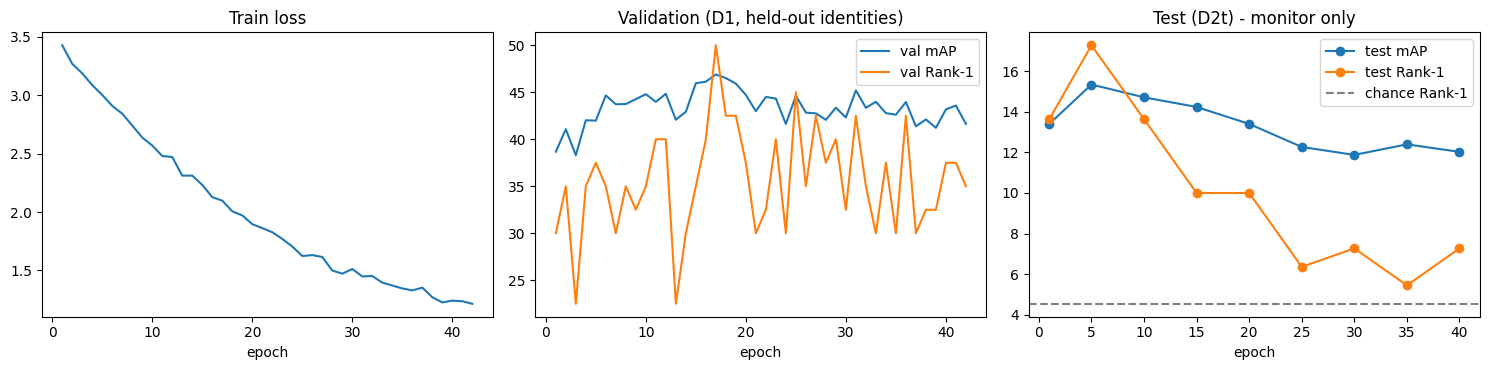

In [9]:
final_model = build_model(n_classes)
final_model.load_state_dict(torch.load(ckpt_path, map_location=device))

final_val  = eval_val(final_model)
final_test = eval_test(final_model)

print('=' * 100)
show('UNTRAINED  test (D2t)', baseline_test)
show('TRAINED    val  (D1)',  final_val)
show('TRAINED    test (D2t)', final_test)
print('=' * 100)
print('Test CMC (Rank-1..10):', np.round(final_test['cmc'], 1))
print(f"Rank-1 standard error with {final_test['n_queries']} queries is about "
      f"+-{100*np.sqrt(max(final_test['rank1']/100*(1-final_test['rank1']/100),1e-9)/final_test['n_queries']):.1f} points - "
      f"differences smaller than this are noise.")

# --- curves ---
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(history['epoch'], history['loss']); ax[0].set_title('Train loss'); ax[0].set_xlabel('epoch')
ax[1].plot(history['epoch'], history['val_mAP'], label='val mAP'); ax[1].plot(history['epoch'], history['val_R1'], label='val Rank-1')
ax[1].set_title('Validation (D1, held-out identities)'); ax[1].legend(); ax[1].set_xlabel('epoch')
ax[2].plot(history['test_epoch'], history['test_mAP'], 'o-', label='test mAP')
ax[2].plot(history['test_epoch'], history['test_R1'], 'o-', label='test Rank-1')
ax[2].axhline(final_test['chance_rank1'], color='gray', ls='--', label='chance Rank-1')
ax[2].set_title('Test (D2t) - monitor only'); ax[2].legend(); ax[2].set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 10. How to read the results / what to try next

* **Trained val >> trained test:** the model learns identities but not across sessions/environments -> domain shift. Try stronger augmentation, per-session normalisation, or adding some D2-like data to training.
* **Trained test ~ untrained test:** nothing transferable is learned. Try `norm_mode='none'` vs `'graph'`, `graph_mode='dataset'`, a larger `band_k`, or a simpler temporal encoder.
* **Both val and test are low:** more data / more steps (`batches_per_epoch`, `n_epochs`), or lower `dropout`.
* Set `val_id_fraction=0` for a final run on **all** D1 identities (no validation; the last epoch is used).
* Compare several seeds (`CFG['seed']`) — with ~100 probes a single run can differ by several points.